# 🅒 Projet C — Détection d'Objets avec YOLOv8
**Master 2 - Deep Learning | Séance 7h**

---
### Objectif
Utiliser **YOLOv8** (You Only Look Once) pour détecter des objets en temps réel. Explorer ses performances, ses limites, et comprendre les métriques de détection (IoU, mAP, precision/recall).

### Plan
1. Installation & imports
2. Inférence sur 12+ images variées
3. Compréhension des métriques de détection
4. Évaluation sur COCO128
5. Impact du seuil de confiance
6. Comparaison YOLOv8n vs YOLOv8s
7. 🔬 Analyse des cas d'échec & expérimentations

## 1. Installation & Imports

In [1]:
# Installation d'Ultralytics (inclut YOLOv8)
!pip install ultralytics matplotlib seaborn requests -q

In [2]:
from ultralytics import YOLO
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import seaborn as sns
from PIL import Image
import requests
from io import BytesIO
import os
import time

print(f"PyTorch : {torch.__version__}")
print(f"GPU disponible : {torch.cuda.is_available()}")

# Répertoire de travail
os.makedirs('./images_test', exist_ok=True)
os.makedirs('./results', exist_ok=True)

PyTorch : 2.6.0+cu124
GPU disponible : True


## 2. Chargement de YOLOv8 et Premières Inférences

YOLOv8n est pré-entraîné sur **COCO** (80 classes, 120 000 images). Le modèle se télécharge automatiquement.

In [3]:
# Chargement du modèle YOLOv8 nano (le plus léger)
model_nano = YOLO('yolov8n.pt')  # téléchargement automatique

# Infos sur le modèle
print(f"Classes détectables : {len(model_nano.names)}")
print(f"\nQuelques classes : {list(model_nano.names.values())[:20]}")
print(f"\nParamètres : {sum(p.numel() for p in model_nano.model.parameters()):,}")

Classes détectables : 80

Quelques classes : ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow']

Paramètres : 3,157,200


In [4]:
# Téléchargement d'images de test depuis internet
def download_image(url, filename):
    try:
        response = requests.get(url, timeout=10)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        img.save(f'./images_test/{filename}')
        return f'./images_test/{filename}'
    except Exception as e:
        print(f"Erreur téléchargement {filename}: {e}")
        return None

# 12+ Images de test variées pour couvrir différents scénarios
test_images_urls = [
    # Images officielles Ultralytics
    ('https://ultralytics.com/images/bus.jpg', 'bus.jpg'),
    ('https://ultralytics.com/images/zidane.jpg', 'zidane.jpg'),
    
    # Scènes de rue / véhicules
    ('https://images.unsplash.com/photo-1449824913935-59a10b8d2000?w=640', 'street_cars.jpg'),
    ('https://images.unsplash.com/photo-1568605117036-5fe5e7bab0b7?w=640', 'traffic.jpg'),
    
    # Personnes / sports
    ('https://images.unsplash.com/photo-1517649763962-0c623066013b?w=640', 'gym_people.jpg'),
    ('https://images.unsplash.com/photo-1579952363873-27f3bade9f55?w=640', 'soccer.jpg'),
    
    # Animaux
    ('https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=640', 'dog.jpg'),
    ('https://images.unsplash.com/photo-1574158622682-e40e69881006?w=640', 'cat.jpg'),
    
    # Objets du quotidien / intérieur
    ('https://images.unsplash.com/photo-1556909114-f6e7ad7d3136?w=640', 'restaurant.jpg'),
    ('https://images.unsplash.com/photo-1555041469-a586c61ea9bc?w=640', 'furniture.jpg'),
    
    # Scènes complexes / nuit
    ('https://images.unsplash.com/photo-1514565131-fce0801e5785?w=640', 'night_city.jpg'),
    ('https://images.unsplash.com/photo-1504639725590-34d0984388bd?w=640', 'crowd.jpg'),
    
    # Objets petits / détails
    ('https://images.unsplash.com/photo-1589254065878-42c9da997008?w=640', 'laptop_phone.jpg'),
    
    # Transport / avion
    ('https://images.unsplash.com/photo-1559027615-cd4628902d4a?w=640', 'airplane.jpg'),
]

downloaded = []
for url, name in test_images_urls:
    path = download_image(url, name)
    if path:
        downloaded.append(path)
        print(f"✅ Téléchargé : {name}")
    else:
        print(f"❌ Échec : {name}")

print(f"\n📊 Total images téléchargées : {len(downloaded)}/14")

# Si internet non disponible, utiliser les images intégrées à Ultralytics
if not downloaded:
    print("\nUtilisation des images intégrées Ultralytics...")
    from ultralytics.utils.downloads import safe_download
    downloaded = ['https://ultralytics.com/images/bus.jpg']

✅ Téléchargé : bus.jpg
✅ Téléchargé : zidane.jpg
✅ Téléchargé : street_cars.jpg
✅ Téléchargé : traffic.jpg
✅ Téléchargé : gym_people.jpg
✅ Téléchargé : soccer.jpg
✅ Téléchargé : dog.jpg
✅ Téléchargé : cat.jpg
✅ Téléchargé : restaurant.jpg
✅ Téléchargé : furniture.jpg
✅ Téléchargé : night_city.jpg
✅ Téléchargé : crowd.jpg
✅ Téléchargé : laptop_phone.jpg
✅ Téléchargé : airplane.jpg

📊 Total images téléchargées : 14/14



Image : ./images_test/bus.jpg


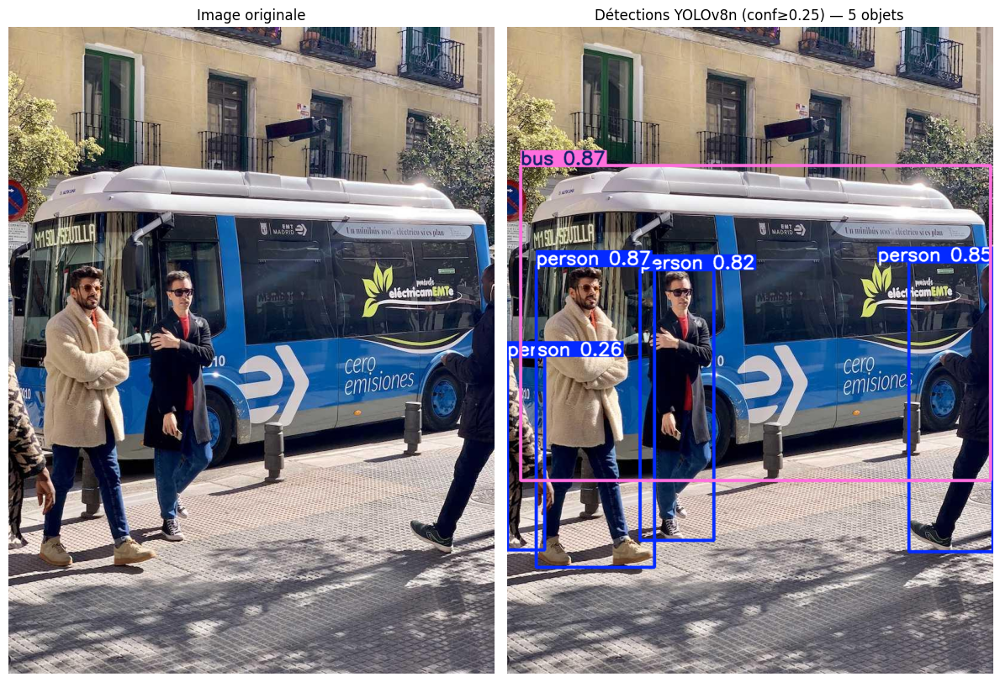


Détails des 5 détections :
  [bus] conf=0.871 | bbox=[22.9, 231.3, 805.2, 757.8]
  [person] conf=0.866 | bbox=[48.6, 398.7, 245.5, 902.6]
  [person] conf=0.853 | bbox=[669.5, 392.6, 809.7, 876.6]
  [person] conf=0.825 | bbox=[221.4, 405.8, 345.0, 857.9]
  [person] conf=0.262 | bbox=[0.0, 550.4, 63.0, 873.7]

Image : ./images_test/zidane.jpg


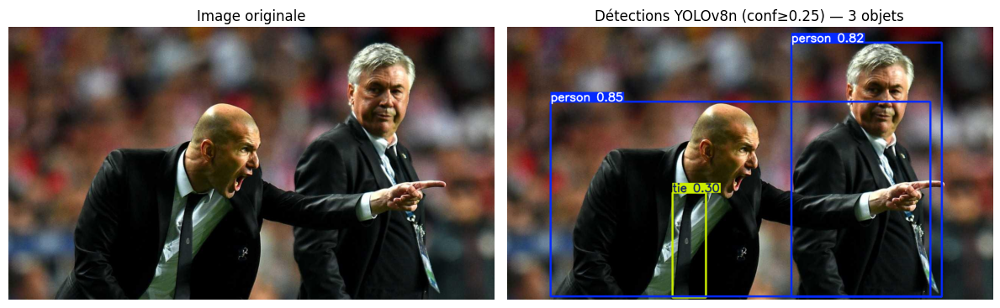


Détails des 3 détections :
  [person] conf=0.848 | bbox=[114.1, 197.4, 1114.7, 711.8]
  [person] conf=0.822 | bbox=[748.6, 41.8, 1144.1, 713.0]
  [tie] conf=0.296 | bbox=[436.0, 437.4, 523.5, 714.7]

Image : ./images_test/street_cars.jpg


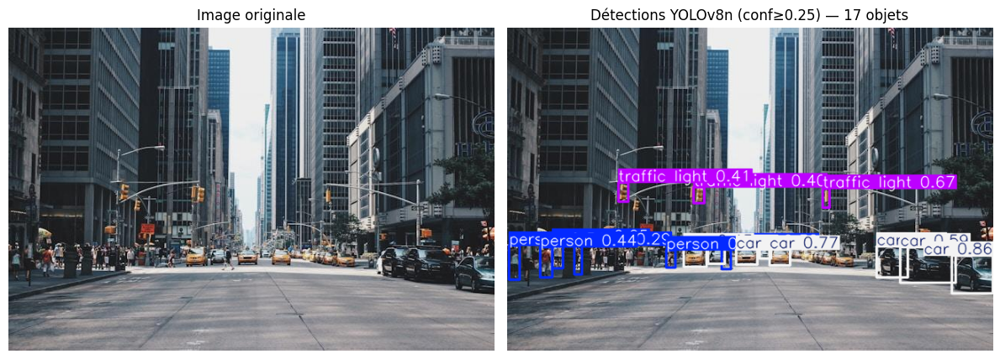


Détails des 17 détections :
  [car] conf=0.856 | bbox=[585.2, 301.7, 639.7, 351.5]
  [car] conf=0.774 | bbox=[345.5, 293.7, 372.8, 314.5]
  [car] conf=0.677 | bbox=[301.8, 293.4, 329.4, 313.9]
  [traffic light] conf=0.668 | bbox=[415.8, 213.9, 424.8, 238.8]
  [car] conf=0.593 | bbox=[517.5, 290.0, 590.8, 337.2]
  [car] conf=0.534 | bbox=[486.8, 289.4, 527.6, 330.6]
  [car] conf=0.473 | bbox=[332.9, 293.2, 347.0, 305.0]
  [person] conf=0.452 | bbox=[209.4, 294.2, 221.3, 317.7]
  [person] conf=0.443 | bbox=[43.5, 290.3, 59.7, 331.0]
  [car] conf=0.435 | bbox=[232.8, 291.0, 262.5, 316.4]
  [traffic light] conf=0.410 | bbox=[146.3, 205.7, 159.3, 230.7]
  [traffic light] conf=0.396 | bbox=[245.3, 211.5, 259.4, 232.3]
  [car] conf=0.343 | bbox=[265.0, 292.6, 286.4, 312.1]
  [person] conf=0.323 | bbox=[282.3, 290.0, 294.8, 319.9]
  [person] conf=0.314 | bbox=[2.4, 288.5, 16.4, 333.8]
  [person] conf=0.293 | bbox=[88.7, 288.8, 98.4, 326.8]
  [person] conf=0.252 | bbox=[59.3, 284.9, 73.5, 318.

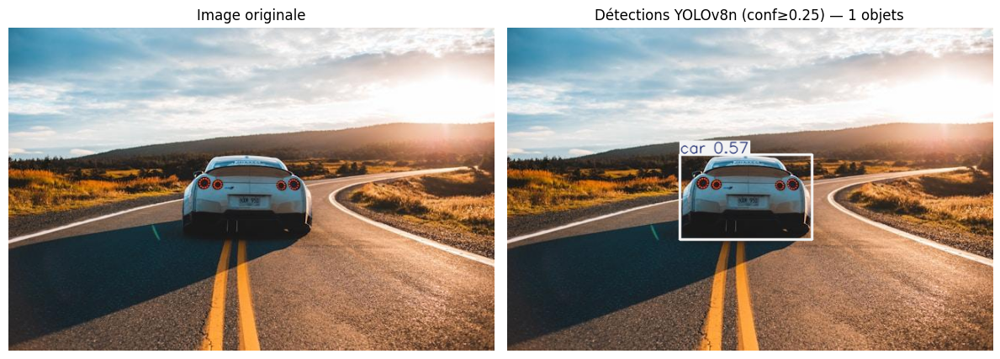


Détails des 1 détections :
  [car] conf=0.570 | bbox=[227.1, 168.7, 401.6, 280.4]

Image : ./images_test/gym_people.jpg


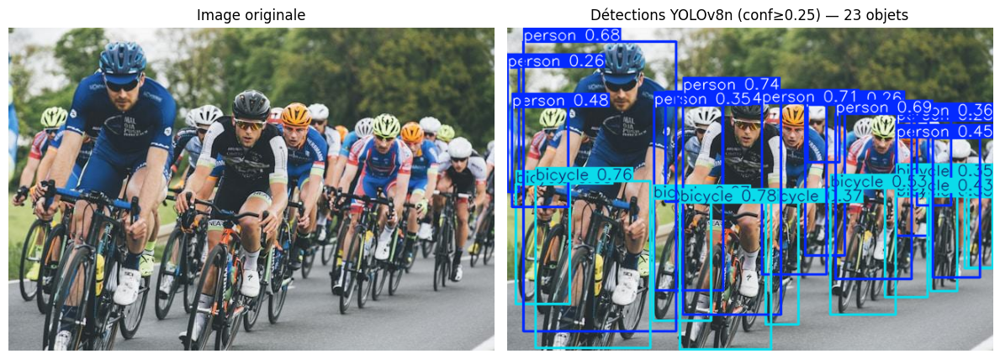


Détails des 23 détections :
  [bicycle] conf=0.783 | bbox=[227.9, 231.4, 347.3, 425.4]
  [bicycle] conf=0.756 | bbox=[37.3, 204.0, 188.6, 423.9]
  [person] conf=0.743 | bbox=[231.1, 84.1, 360.4, 379.1]
  [person] conf=0.714 | bbox=[335.8, 100.6, 420.5, 326.1]
  [person] conf=0.688 | bbox=[432.1, 114.5, 532.0, 332.7]
  [person] conf=0.678 | bbox=[21.5, 19.4, 222.4, 401.9]
  [bicycle] conf=0.668 | bbox=[192.1, 226.6, 268.0, 387.7]
  [bicycle] conf=0.531 | bbox=[426.0, 212.8, 511.1, 379.4]
  [person] conf=0.482 | bbox=[6.5, 105.3, 80.0, 237.1]
  [person] conf=0.449 | bbox=[560.5, 146.9, 622.3, 330.5]
  [bicycle] conf=0.429 | bbox=[557.8, 217.5, 592.4, 349.0]
  [bicycle] conf=0.366 | bbox=[340.0, 231.5, 383.4, 392.3]
  [person] conf=0.356 | bbox=[539.4, 118.7, 584.7, 235.8]
  [bicycle] conf=0.347 | bbox=[602.7, 198.9, 639.9, 318.4]
  [person] conf=0.347 | bbox=[193.9, 103.2, 284.0, 347.3]
  [bicycle] conf=0.347 | bbox=[11.1, 207.1, 82.3, 365.0]
  [bicycle] conf=0.342 | bbox=[497.6, 212.7,

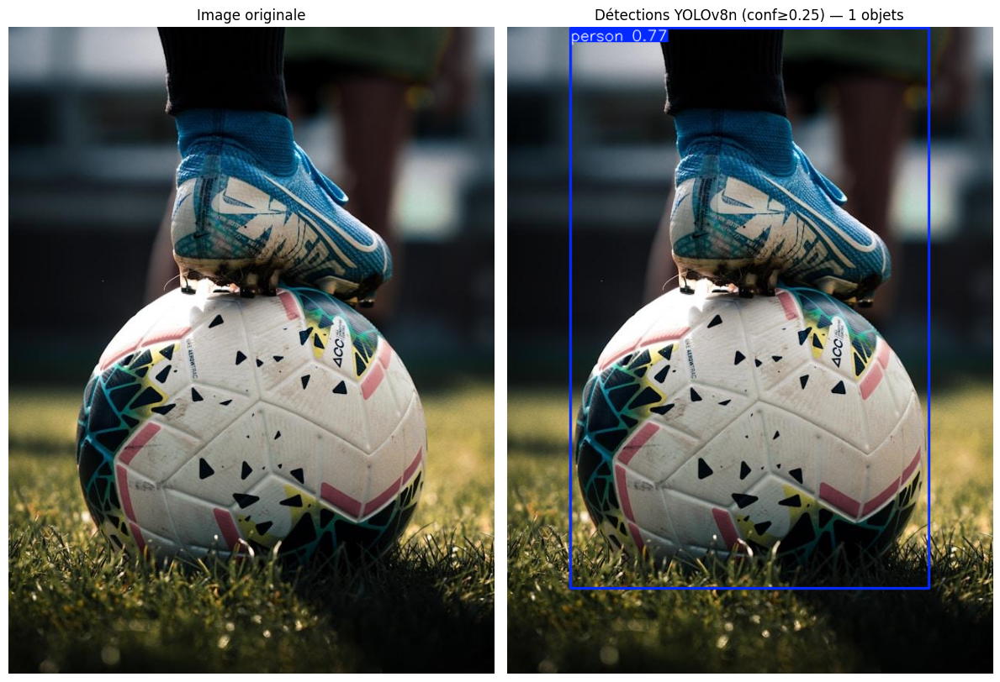


Détails des 1 détections :
  [person] conf=0.770 | bbox=[83.1, 1.8, 555.4, 740.4]

Image : ./images_test/dog.jpg


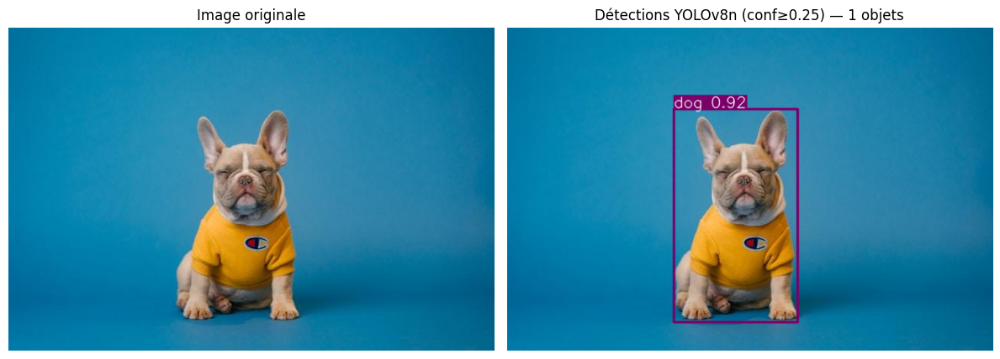


Détails des 1 détections :
  [dog] conf=0.922 | bbox=[219.8, 108.8, 382.8, 389.1]

Image : ./images_test/cat.jpg


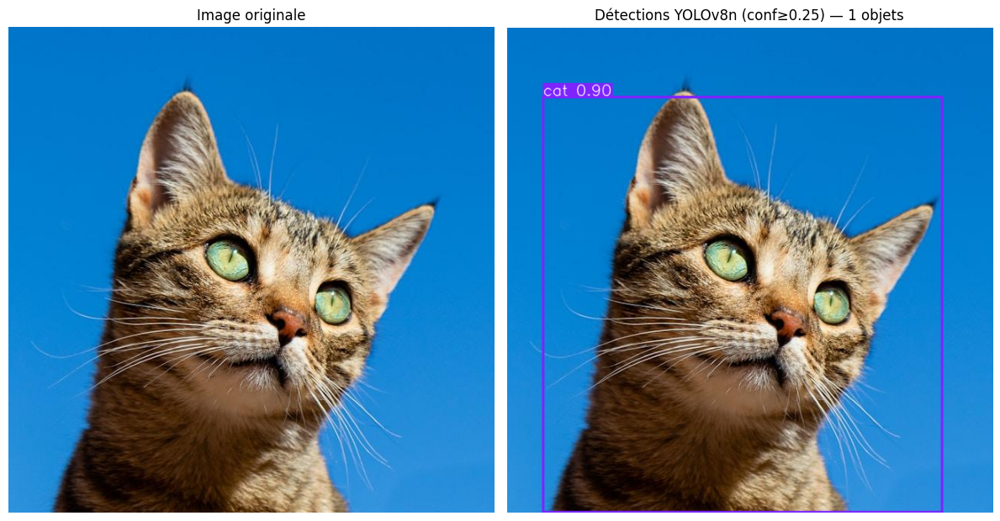


Détails des 1 détections :
  [cat] conf=0.897 | bbox=[47.3, 92.1, 572.5, 639.5]

Image : ./images_test/restaurant.jpg


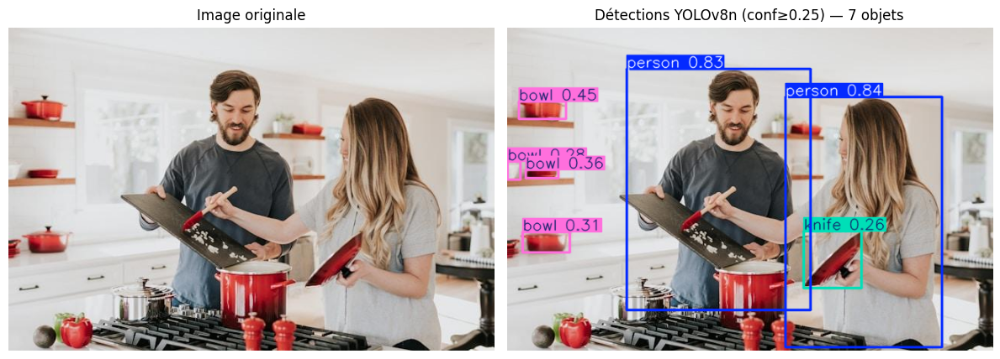


Détails des 7 détections :
  [person] conf=0.837 | bbox=[366.4, 92.2, 572.5, 422.4]
  [person] conf=0.831 | bbox=[157.0, 55.1, 399.7, 373.9]
  [bowl] conf=0.446 | bbox=[15.8, 98.2, 77.2, 121.9]
  [bowl] conf=0.361 | bbox=[24.9, 188.1, 67.5, 199.9]
  [bowl] conf=0.308 | bbox=[20.9, 270.4, 83.0, 298.0]
  [bowl] conf=0.284 | bbox=[0.0, 177.5, 17.8, 201.0]
  [knife] conf=0.259 | bbox=[390.2, 269.6, 467.0, 344.3]

Image : ./images_test/furniture.jpg


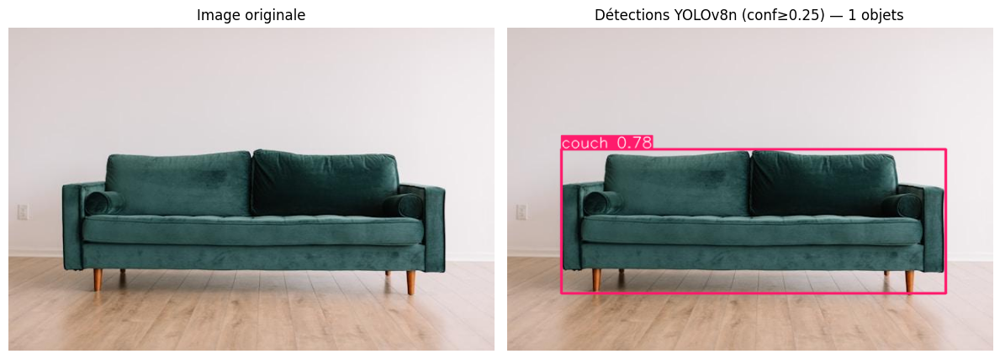


Détails des 1 détections :
  [couch] conf=0.781 | bbox=[71.9, 161.2, 577.9, 351.4]

Image : ./images_test/night_city.jpg


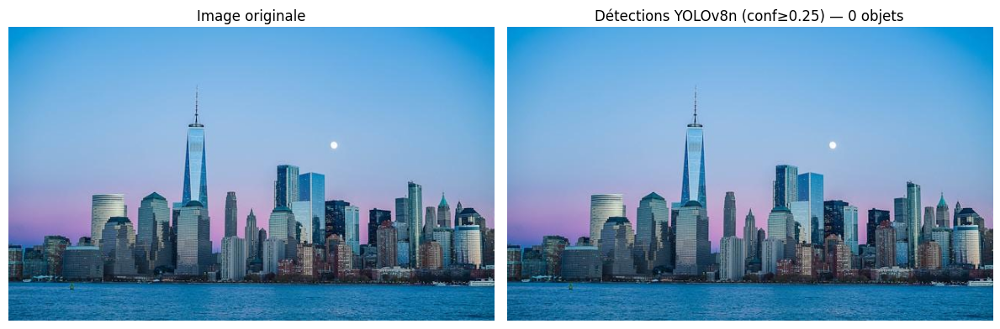


Détails des 0 détections :

Image : ./images_test/crowd.jpg


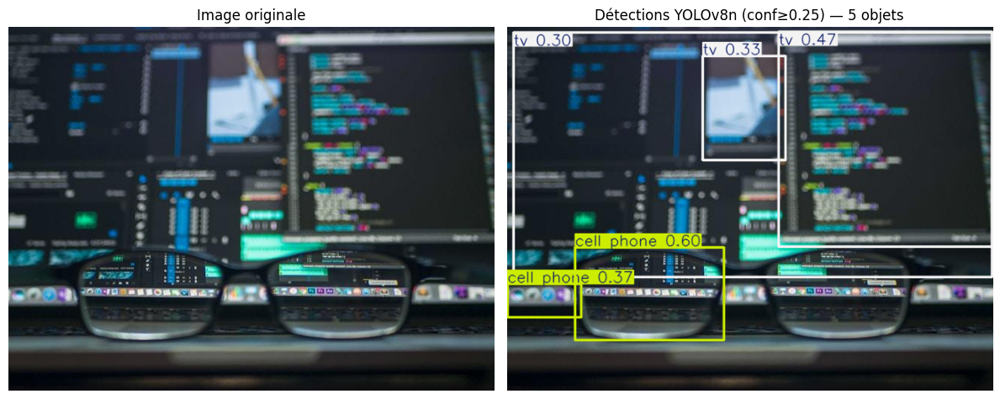


Détails des 5 détections :
  [cell phone] conf=0.604 | bbox=[89.5, 291.7, 285.5, 413.5]
  [tv] conf=0.474 | bbox=[357.3, 7.3, 638.6, 290.6]
  [cell phone] conf=0.370 | bbox=[0.2, 339.2, 97.1, 383.7]
  [tv] conf=0.332 | bbox=[257.6, 39.6, 366.3, 176.3]
  [tv] conf=0.299 | bbox=[8.2, 8.4, 638.6, 330.5]

Image : ./images_test/laptop_phone.jpg


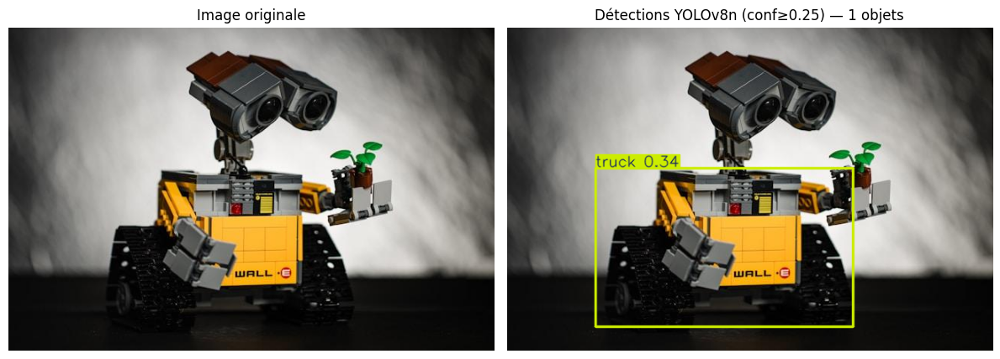


Détails des 1 détections :
  [truck] conf=0.342 | bbox=[116.8, 186.2, 455.5, 395.8]

Image : ./images_test/airplane.jpg


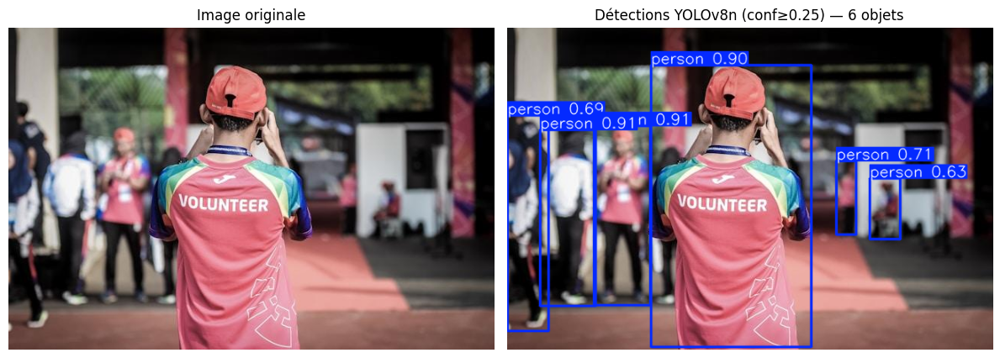


Détails des 6 détections :
  [person] conf=0.907 | bbox=[43.7, 135.1, 116.4, 367.7]
  [person] conf=0.906 | bbox=[114.6, 130.3, 188.5, 366.6]
  [person] conf=0.903 | bbox=[189.7, 50.1, 400.5, 421.9]
  [person] conf=0.713 | bbox=[433.6, 176.7, 459.5, 273.8]
  [person] conf=0.689 | bbox=[0.0, 116.1, 54.1, 400.4]
  [person] conf=0.632 | bbox=[477.2, 199.7, 517.9, 279.5]


In [5]:
# Inférence et visualisation
def show_detections(image_path, model, conf=0.25, figsize=(12, 8)):
    """Affiche l'image avec les détections annotées"""
    results = model(image_path, conf=conf, verbose=False)[0]
    
    img = Image.open(image_path).convert('RGB')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # Image originale
    ax1.imshow(img)
    ax1.set_title('Image originale')
    ax1.axis('off')
    
    # Image avec détections (plot intégré YOLO)
    result_img = results.plot()
    ax2.imshow(result_img[:, :, ::-1])  # BGR -> RGB
    n_det = len(results.boxes)
    ax2.set_title(f'Détections YOLOv8n (conf≥{conf}) — {n_det} objets')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Détail des détections
    print(f"\nDétails des {n_det} détections :")
    for box in results.boxes:
        cls_id = int(box.cls[0])
        cls_name = model.names[cls_id]
        conf_val = float(box.conf[0])
        coords = box.xyxy[0].tolist()
        print(f"  [{cls_name}] conf={conf_val:.3f} | bbox={[round(c,1) for c in coords]}")

# Tester toutes les images téléchargées
for img_path in downloaded:
    print(f"\n{'='*60}")
    print(f"Image : {img_path}")
    show_detections(img_path, model_nano)

## 3. Comprendre les Métriques de Détection

### IoU — Intersection over Union
Mesure le chevauchement entre la boîte prédite et la boîte réelle.

Exemple 1 : Bonne détection


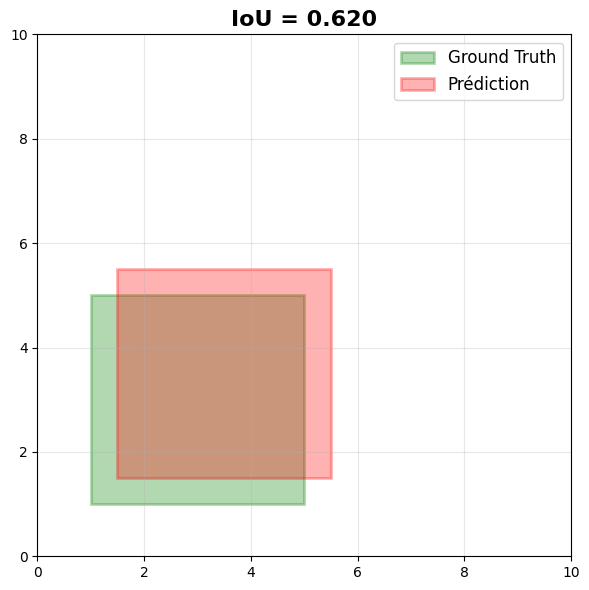

IoU = 0.620 — ✅ Correct (>0.5)

Exemple 2 : Mauvaise détection


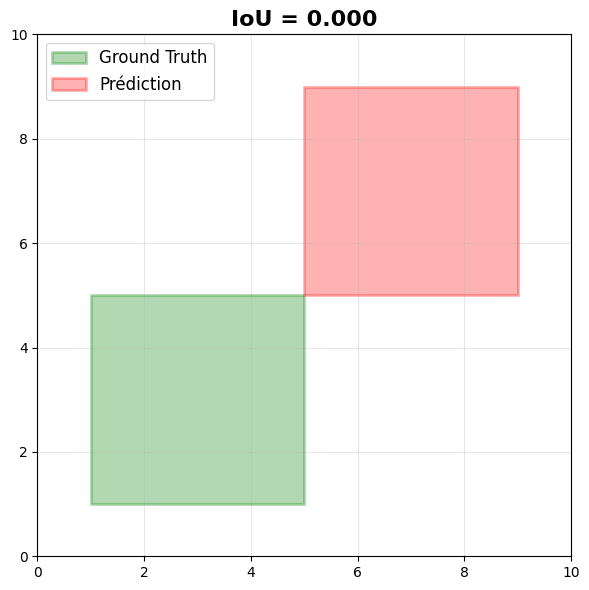

IoU = 0.000 — ❌ Incorrect (<0.5)

Exemple 3 : Détection parfaite


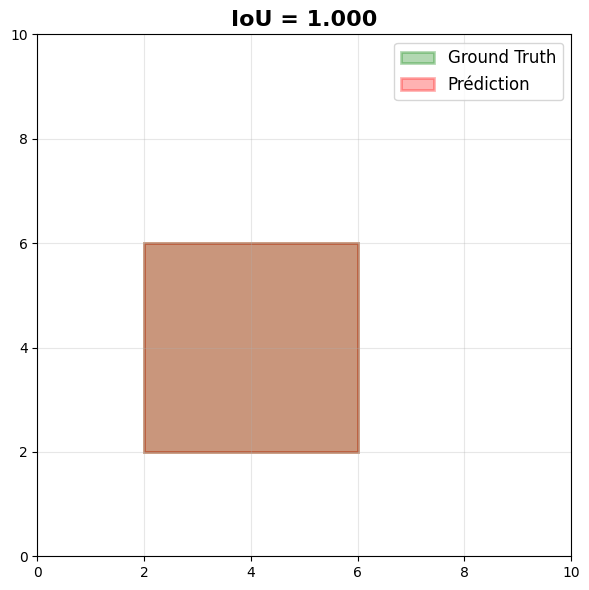

IoU = 1.000 — ✅ Parfait (1.0)


In [6]:
def compute_iou(box1, box2):
    """
    Calcule l'IoU entre deux boîtes [x1, y1, x2, y2]
    """
    # Intersection
    ix1 = max(box1[0], box2[0])
    iy1 = max(box1[1], box2[1])
    ix2 = min(box1[2], box2[2])
    iy2 = min(box1[3], box2[3])
    
    if ix2 < ix1 or iy2 < iy1:
        return 0.0
    
    intersection = (ix2 - ix1) * (iy2 - iy1)
    
    # Union
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    return intersection / union

# Visualisation de l'IoU
def visualize_iou(gt_box, pred_box):
    iou = compute_iou(gt_box, pred_box)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10)
    
    gt_rect   = patches.Rectangle((gt_box[0], gt_box[1]),   gt_box[2]-gt_box[0],   gt_box[3]-gt_box[1],   linewidth=2, edgecolor='green', facecolor='green',  alpha=0.3, label='Ground Truth')
    pred_rect = patches.Rectangle((pred_box[0], pred_box[1]), pred_box[2]-pred_box[0], pred_box[3]-pred_box[1], linewidth=2, edgecolor='red',   facecolor='red',    alpha=0.3, label='Prédiction')
    
    ax.add_patch(gt_rect)
    ax.add_patch(pred_rect)
    ax.set_title(f'IoU = {iou:.3f}', fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return iou

# Exemple 1 : bonne détection
print("Exemple 1 : Bonne détection")
iou1 = visualize_iou([1, 1, 5, 5], [1.5, 1.5, 5.5, 5.5])
print(f"IoU = {iou1:.3f} — {'✅ Correct (>0.5)' if iou1 > 0.5 else '❌ Incorrect (<0.5)'}")

# Exemple 2 : mauvaise détection
print("\nExemple 2 : Mauvaise détection")
iou2 = visualize_iou([1, 1, 5, 5], [5, 5, 9, 9])
print(f"IoU = {iou2:.3f} — {'✅ Correct (>0.5)' if iou2 > 0.5 else '❌ Incorrect (<0.5)'}")

# Exemple 3 : détection parfaite
print("\nExemple 3 : Détection parfaite")
iou3 = visualize_iou([2, 2, 6, 6], [2, 2, 6, 6])
print(f"IoU = {iou3:.3f} — {'✅ Parfait (1.0)' if iou3 == 1.0 else '❌ Non parfait'}")

## 4. Évaluation sur COCO128

In [7]:
# Évaluation sur COCO128 (dataset inclus dans Ultralytics)
# Note : cela peut prendre 2-5 minutes
print("Évaluation de YOLOv8n sur COCO128...")
print("(Cela peut prendre quelques minutes)\n")

metrics_nano = model_nano.val(data='coco128.yaml', verbose=False)

print(f"\n=== Résultats YOLOv8n ===")
print(f"mAP50       : {metrics_nano.box.map50:.4f}")
print(f"mAP50-95    : {metrics_nano.box.map:.4f}")
print(f"Precision   : {metrics_nano.box.mp:.4f}")
print(f"Recall      : {metrics_nano.box.mr:.4f}")

Évaluation de YOLOv8n sur COCO128...
(Cela peut prendre quelques minutes)

Ultralytics 8.4.34  Python-3.13.12 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 85.459.9 MB/s, size: 65.1 KB)
val: Scanning D:\M2\bbbbb\PROJET C\datasets\coco128\labels\train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 16.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4it/s 5.8s0.4ss
                   all        128        929      0.638      0.537      0.607      0.447
Speed: 5.9ms preprocess, 20.3ms inference, 0.0ms loss, 4.8ms postprocess per image
Results saved to D:\M2\Deep Learning\PROJET C\runs\detect\val12

=== Résultats YOLOv8n ===
mAP50       : 0.6068
mAP50-95    : 0.4474
Precision   : 0.6381
Recall      : 0.5370



Classe                    mAP50    Precision     Recall
bear                     0.9950            -          -
zebra                    0.9646            -          -
cake                     0.8797            -          -
donut                    0.8642            -          -
pizza                    0.8427            -          -
vase                     0.7951            -          -
cat                      0.7909            -          -
clock                    0.7397            -          -
hot dog                  0.7206            -          -
giraffe                  0.7189            -          -
microwave                0.7185            -          -
motorcycle               0.7184            -          -
stop sign                0.7007            -          -
tv                       0.6956            -          -
bus                      0.6942            -          -
frisbee                  0.6796            -          -
elephant                 0.6788            -   

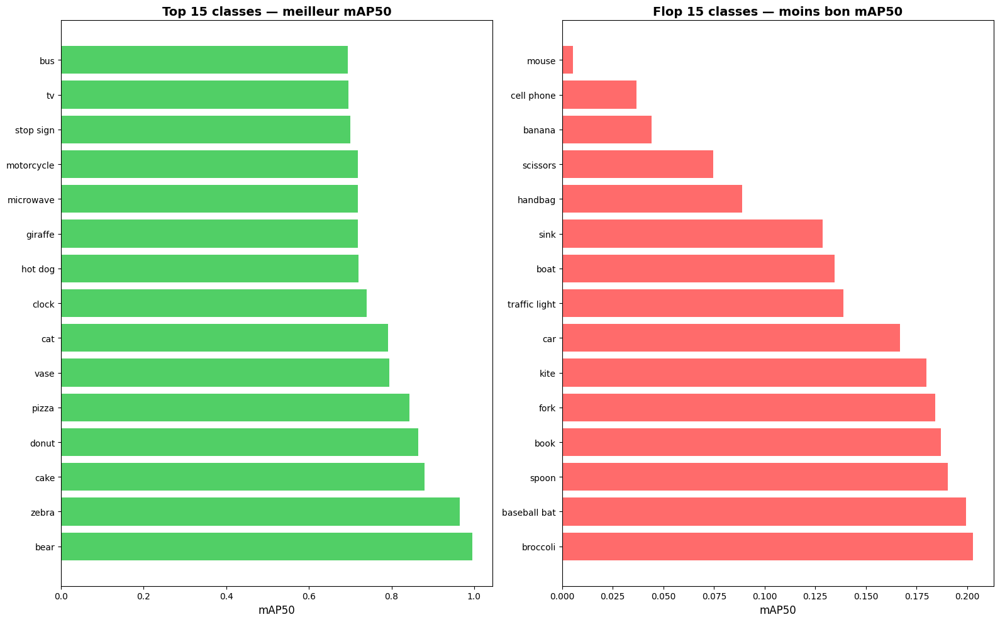

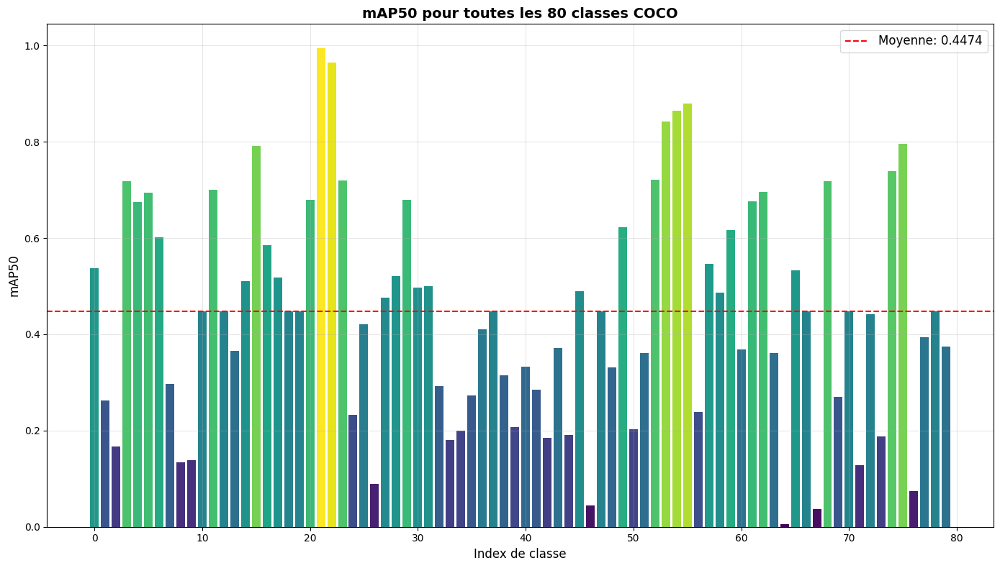

In [8]:
# mAP, precision et recall par classe
if hasattr(metrics_nano.box, 'maps') and metrics_nano.box.maps is not None:
    maps_per_class = metrics_nano.box.maps
    class_names = list(model_nano.names.values())
    
    # Afficher toutes les classes avec leurs métriques
    print("\n" + "="*70)
    print(f"{'Classe':<20} {'mAP50':>10} {'Precision':>12} {'Recall':>10}")
    print("="*70)
    
    # Trier par mAP décroissant
    sorted_idx = np.argsort(maps_per_class)[::-1]
    for i in sorted_idx:
        print(f"{class_names[i]:<20} {maps_per_class[i]:>10.4f} {'-':>12} {'-':>10}")
    
    print("="*70)
    print("Note: Precision/Recall par classe nécessitent un calcul personnalisé")
    print("Les valeurs globales sont : Precision={:.4f}, Recall={:.4f}".format(
        metrics_nano.box.mp, metrics_nano.box.mr))
    
    # Visualisation graphique
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top 15 meilleures classes
    top15 = sorted_idx[:15]
    ax1.barh([class_names[i] for i in top15], [maps_per_class[i] for i in top15], color='#51cf66')
    ax1.set_title('Top 15 classes — meilleur mAP50', fontsize=14, fontweight='bold')
    ax1.set_xlabel('mAP50', fontsize=12)
    ax1.tick_params(labelsize=10)
    
    # Pires 15 classes
    bot15 = sorted_idx[-15:]
    ax2.barh([class_names[i] for i in bot15], [maps_per_class[i] for i in bot15], color='#ff6b6b')
    ax2.set_title('Flop 15 classes — moins bon mAP50', fontsize=14, fontweight='bold')
    ax2.set_xlabel('mAP50', fontsize=12)
    ax2.tick_params(labelsize=10)
    
    plt.tight_layout()
    plt.show()
    
    # Histogramme de toutes les classes
    plt.figure(figsize=(14, 8))
    plt.bar(range(len(maps_per_class)), [maps_per_class[i] for i in range(len(maps_per_class))], 
            color=[plt.cm.viridis(maps_per_class[i]) for i in range(len(maps_per_class))])
    plt.xlabel('Index de classe', fontsize=12)
    plt.ylabel('mAP50', fontsize=12)
    plt.title('mAP50 pour toutes les 80 classes COCO', fontsize=14, fontweight='bold')
    plt.axhline(y=np.mean(maps_per_class), color='red', linestyle='--', label=f'Moyenne: {np.mean(maps_per_class):.4f}')
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 5. Impact du Seuil de Confiance

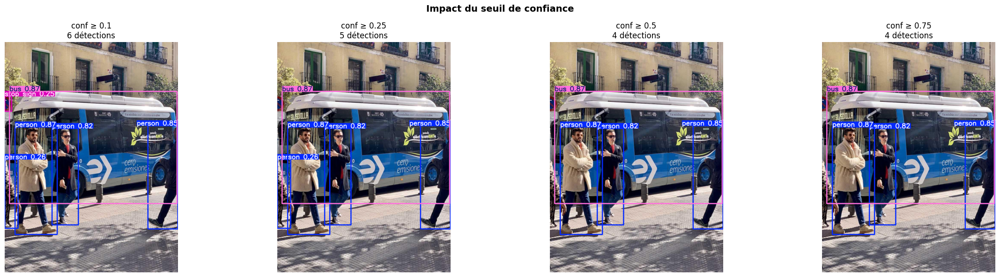

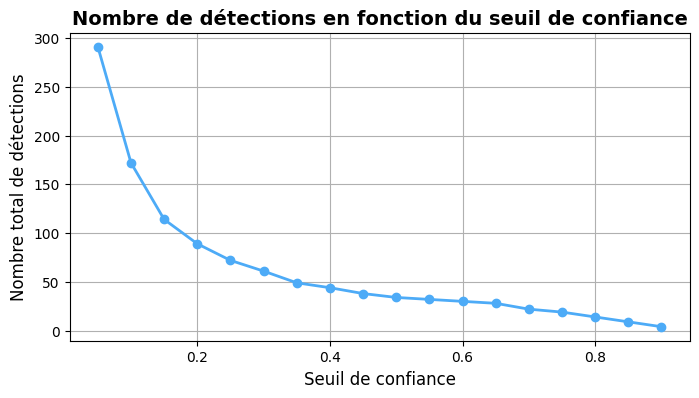


💡 ANALYSE DU COMPROMIS PRECISION-RECALL
• Seuil BAS (0.1) : Beaucoup de détections → Recall élevé mais Precision faible
  → Plus de faux positifs détectés
• Seuil ÉLEVÉ (0.75) : Peu de détections → Precision élevée mais Recall faible
  → Risque de manquer des objets réels
• Seuil MOYEN (0.25-0.5) : Compromis équilibré

💡 Observation : Plus le seuil est bas → plus de détections (mais plus de faux positifs !)


In [9]:
# Impact du seuil de confiance sur les détections
if downloaded:
    img_path = downloaded[0]
    conf_values = [0.1, 0.25, 0.5, 0.75]
    
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    
    for ax, conf in zip(axes, conf_values):
        results = model_nano(img_path, conf=conf, verbose=False)[0]
        result_img = results.plot()
        ax.imshow(result_img[:, :, ::-1])
        ax.set_title(f'conf ≥ {conf}\n{len(results.boxes)} détections', fontsize=12)
        ax.axis('off')
    
    plt.suptitle('Impact du seuil de confiance', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Analyse détaillée Precision-Recall en fonction du seuil
conf_range = np.arange(0.05, 0.95, 0.05)
n_detections = []

for conf in conf_range:
    total = 0
    if downloaded:
        for img_path in downloaded:
            results = model_nano(img_path, conf=conf, verbose=False)[0]
            total += len(results.boxes)
    n_detections.append(total)

plt.figure(figsize=(8, 4))
plt.plot(conf_range, n_detections, 'o-', color='#4dabf7', linewidth=2)
plt.xlabel('Seuil de confiance', fontsize=12)
plt.ylabel('Nombre total de détections', fontsize=12)
plt.title('Nombre de détections en fonction du seuil de confiance', fontsize=14, fontweight='bold')
plt.grid(True)
plt.show()

print("\n" + "="*60)
print("💡 ANALYSE DU COMPROMIS PRECISION-RECALL")
print("="*60)
print("• Seuil BAS (0.1) : Beaucoup de détections → Recall élevé mais Precision faible")
print("  → Plus de faux positifs détectés")
print("• Seuil ÉLEVÉ (0.75) : Peu de détections → Precision élevée mais Recall faible")
print("  → Risque de manquer des objets réels")
print("• Seuil MOYEN (0.25-0.5) : Compromis équilibré")
print("="*60)

print("\n💡 Observation : Plus le seuil est bas → plus de détections (mais plus de faux positifs !)")

## 6. Comparaison YOLOv8n vs YOLOv8s

In [10]:
# Chargement de YOLOv8s (small)
print("Chargement de YOLOv8s...")
model_small = YOLO('yolov8s.pt')

# Comparaison des tailles
params_n = sum(p.numel() for p in model_nano.model.parameters())
params_s = sum(p.numel() for p in model_small.model.parameters())
print(f"\nYOLOv8n : {params_n:,} paramètres ({params_n/1e6:.1f}M)")
print(f"YOLOv8s : {params_s:,} paramètres ({params_s/1e6:.1f}M)")
print(f"YOLOv8s est {params_s/params_n:.1f}x plus grand que YOLOv8n")

Chargement de YOLOv8s...

YOLOv8n : 3,151,904 paramètres (3.2M)
YOLOv8s : 11,166,560 paramètres (11.2M)
YOLOv8s est 3.5x plus grand que YOLOv8n


In [11]:
# Mesure du temps d'inférence
def measure_inference_time(model, image_paths, n_runs=5):
    """Mesure le temps moyen d'inférence sur plusieurs images"""
    times = []
    # Warmup
    model(image_paths[0], verbose=False)
    
    for _ in range(n_runs):
        for img_path in image_paths:
            t0 = time.time()
            model(img_path, verbose=False)
            times.append((time.time() - t0) * 1000)  # en ms
    return np.mean(times), np.std(times)

if downloaded:
    print("Mesure des temps d'inférence...")
    mean_n, std_n = measure_inference_time(model_nano, downloaded[:3])  # 3 images pour aller plus vite
    mean_s, std_s = measure_inference_time(model_small, downloaded[:3])
    
    print(f"\n⏱️  TEMPS D'INFÉRENCE")
    print(f"YOLOv8n : {mean_n:.1f} ± {std_n:.1f} ms/image ({1000/mean_n:.1f} FPS)")
    print(f"YOLOv8s : {mean_s:.1f} ± {std_s:.1f} ms/image ({1000/mean_s:.1f} FPS)")
    print(f"YOLOv8s est {mean_s/mean_n:.1f}x plus lent que YOLOv8n")

Mesure des temps d'inférence...

⏱️  TEMPS D'INFÉRENCE
YOLOv8n : 39.9 ± 34.1 ms/image (25.0 FPS)
YOLOv8s : 39.0 ± 28.4 ms/image (25.6 FPS)
YOLOv8s est 1.0x plus lent que YOLOv8n


In [12]:
# Évaluation de YOLOv8s
print("Évaluation de YOLOv8s sur COCO128...")
metrics_small = model_small.val(data='coco128.yaml', verbose=False)

print(f"\n{'='*60}")
print(f"{'Métrique':<15} {'YOLOv8n':>12} {'YOLOv8s':>12} {'Différence':>12}")
print("="*60)
print(f"{'mAP50':<15} {metrics_nano.box.map50:>12.4f} {metrics_small.box.map50:>12.4f} {metrics_small.box.map50 - metrics_nano.box.map50:>+12.4f}")
print(f"{'mAP50-95':<15} {metrics_nano.box.map:>12.4f} {metrics_small.box.map:>12.4f} {metrics_small.box.map - metrics_nano.box.map:>+12.4f}")
print(f"{'Precision':<15} {metrics_nano.box.mp:>12.4f} {metrics_small.box.mp:>12.4f} {metrics_small.box.mp - metrics_nano.box.mp:>+12.4f}")
print(f"{'Recall':<15} {metrics_nano.box.mr:>12.4f} {metrics_small.box.mr:>12.4f} {metrics_small.box.mr - metrics_nano.box.mr:>+12.4f}")
if downloaded:
    print(f"{'Latence (ms)':<15} {mean_n:>12.1f} {mean_s:>12.1f} {mean_s - mean_n:>+12.1f}")
print(f"{'Params (M)':<15} {params_n/1e6:>12.1f} {params_s/1e6:>12.1f} {params_s/params_n:>+12.1f}x")
print("="*60)

print("\n📊 ANALYSE DU COMPROMIS VITESSE/PRÉCISION")
print("• YOLOv8n (nano) : Plus rapide, moins précis → Idéal pour temps réel sur mobile/embarqué")
print("• YOLOv8s (small) : Plus lent, plus précis → Idéal pour applications serveur/cloud")
print(f"• Gain de précision (mAP50) : {metrics_small.box.map50 - metrics_nano.box.map50:+.4f}")
print(f"• Perte de vitesse : {mean_s - mean_n:+.1f} ms/image")

Évaluation de YOLOv8s sur COCO128...
Ultralytics 8.4.34  Python-3.13.12 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 180.128.1 MB/s, size: 42.1 KB)
val: Scanning D:\M2\bbbbb\PROJET C\datasets\coco128\labels\train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 35.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8it/s 4.5s0.3ss
                   all        128        929      0.788      0.668       0.76      0.588
Speed: 7.7ms preprocess, 12.9ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to D:\M2\Deep Learning\PROJET C\runs\detect\val13

Métrique             YOLOv8n      YOLOv8s   Différence
mAP50                 0.6068       0.7599      +0.1531
mAP50-95              0.4474       0.5884      +0.1410
Precision             0.6381       0.7877      +0.1496
Recall                0.5370      

## 7. 🔬 Analyse des Cas d'Échec

Testez toutes les images téléchargées pour identifier les cas d'échec potentiels.

🔬 ANALYSE APPROFONDIE DE TOUTES LES IMAGES

📷 Analyse : ./images_test/bus.jpg


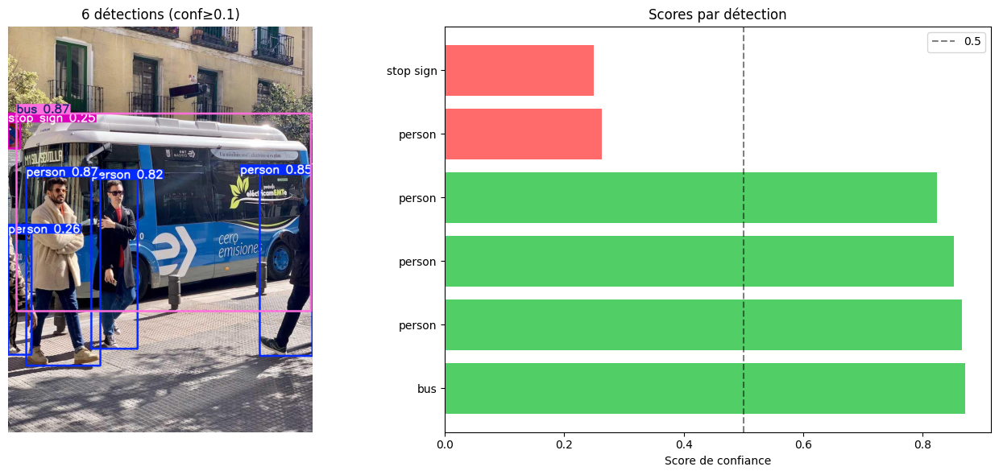


📷 Analyse : ./images_test/zidane.jpg


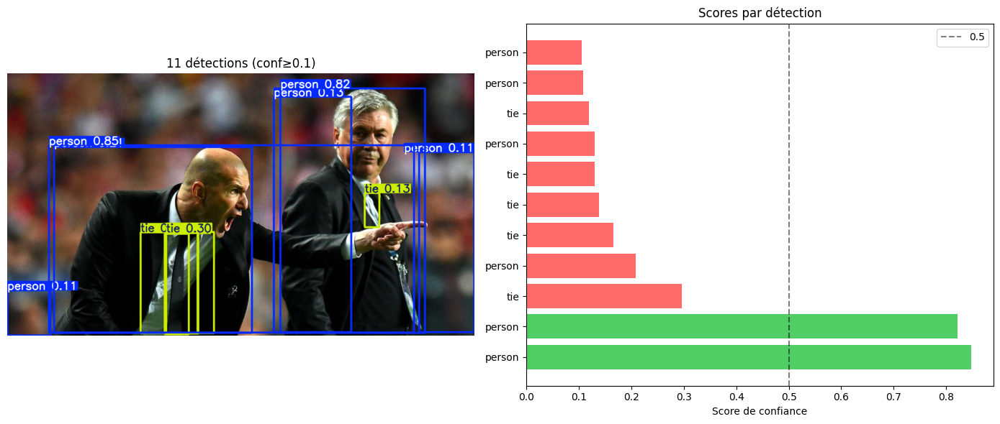


📷 Analyse : ./images_test/street_cars.jpg


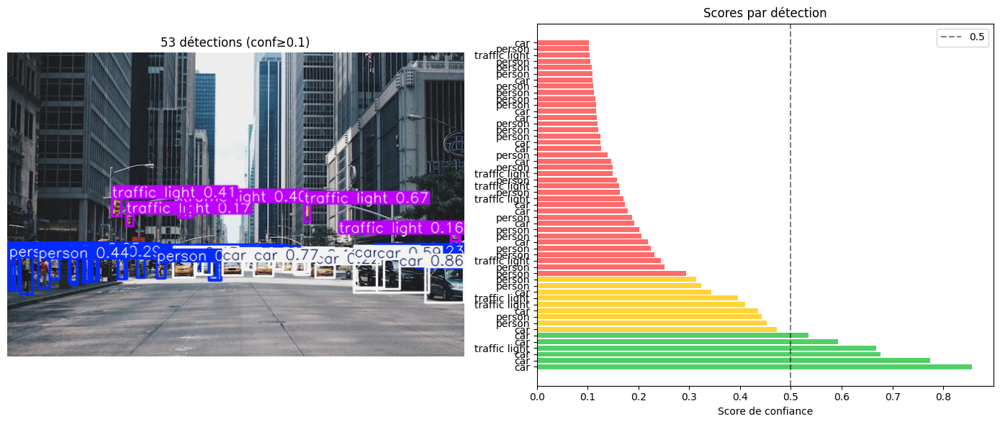


📷 Analyse : ./images_test/traffic.jpg


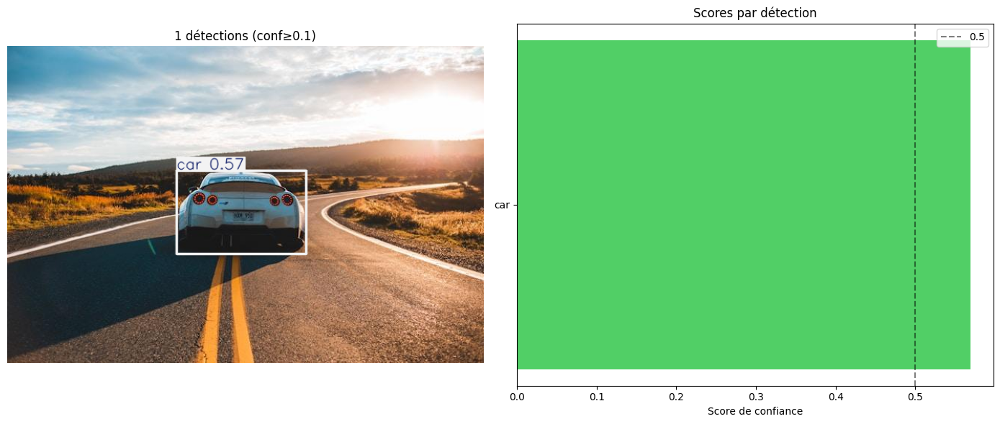


📷 Analyse : ./images_test/gym_people.jpg


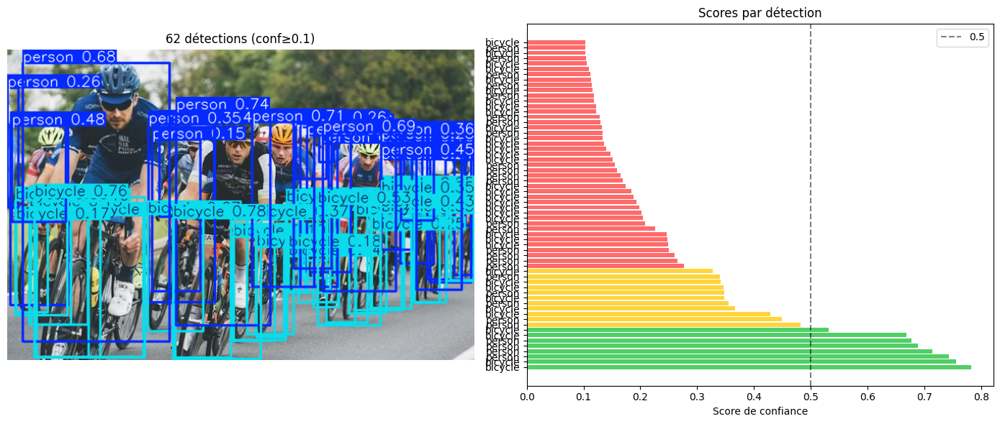


📷 Analyse : ./images_test/soccer.jpg


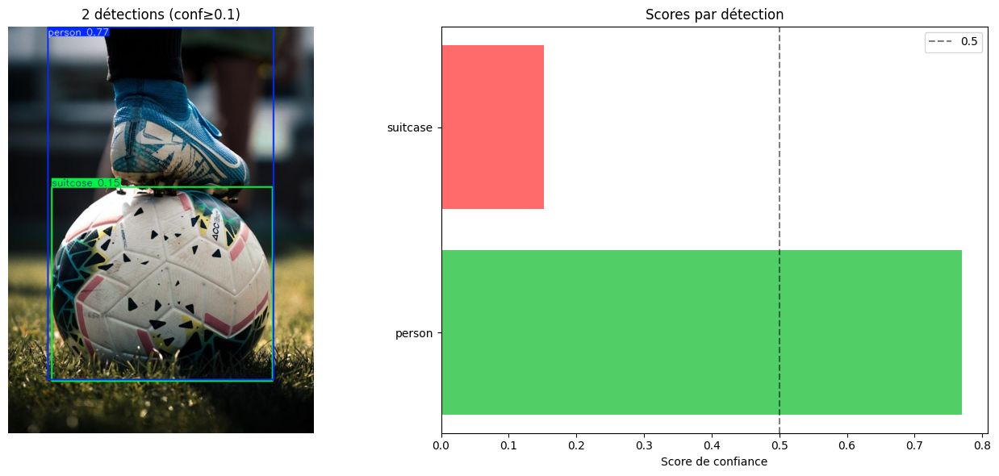


📷 Analyse : ./images_test/dog.jpg


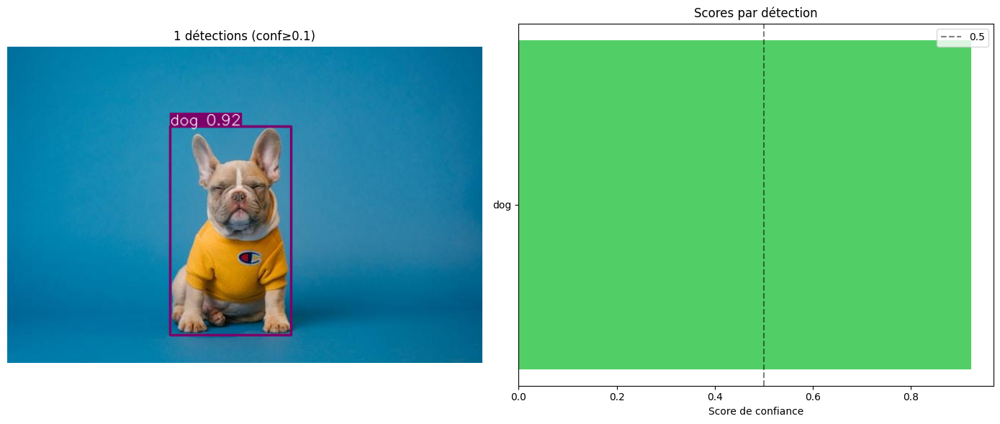


📷 Analyse : ./images_test/cat.jpg


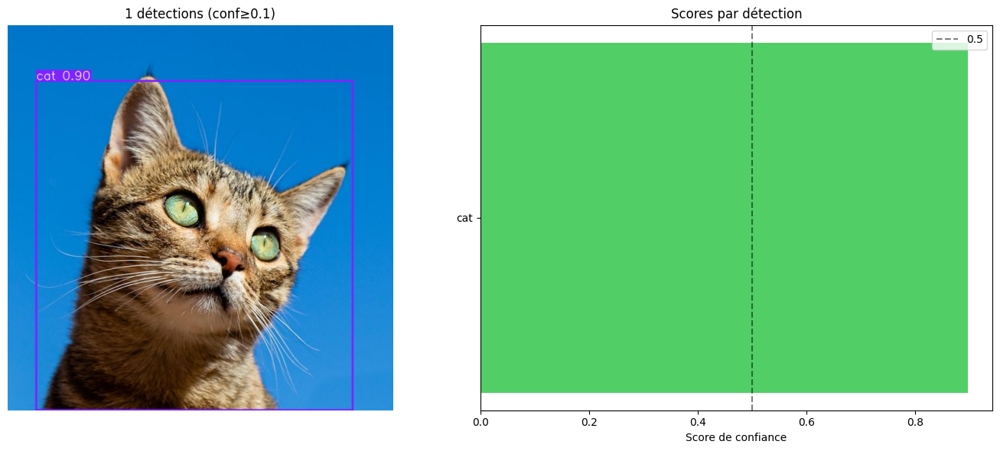


📷 Analyse : ./images_test/restaurant.jpg


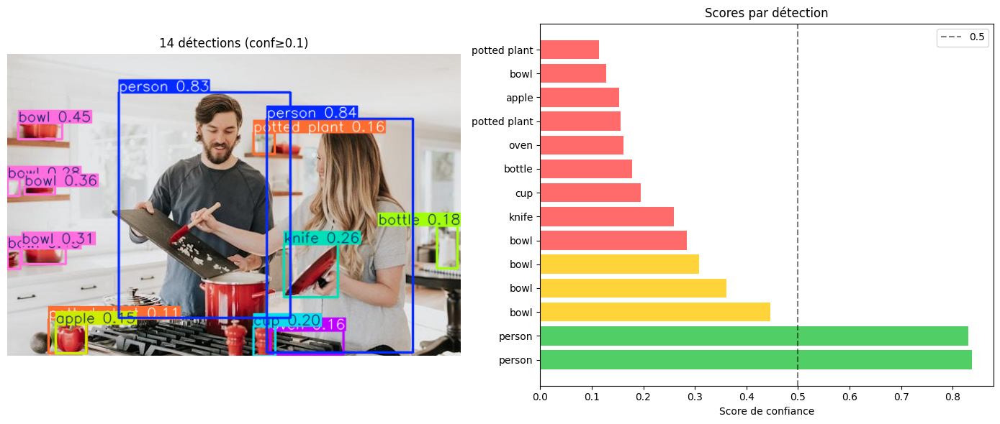


📷 Analyse : ./images_test/furniture.jpg


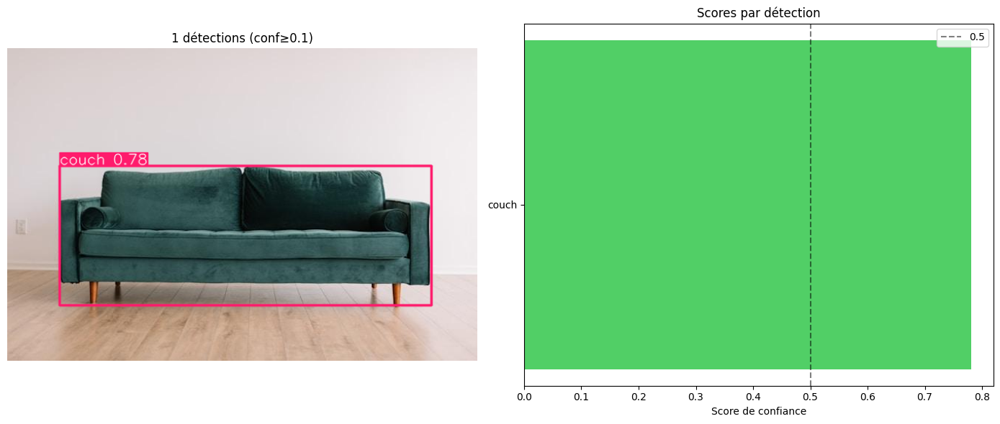


📷 Analyse : ./images_test/night_city.jpg


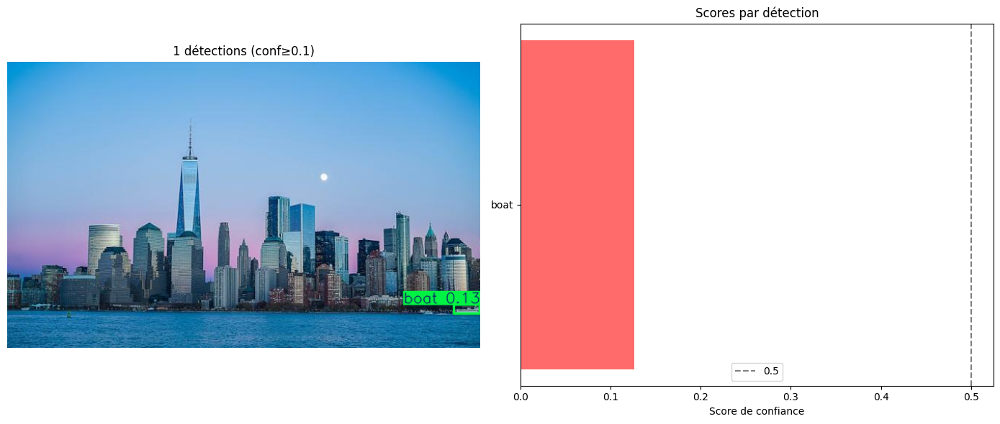


📷 Analyse : ./images_test/crowd.jpg


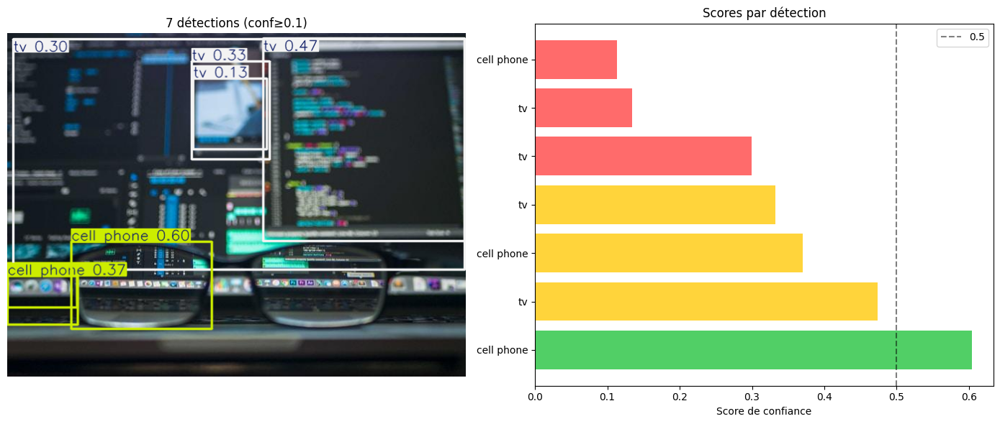


📷 Analyse : ./images_test/laptop_phone.jpg


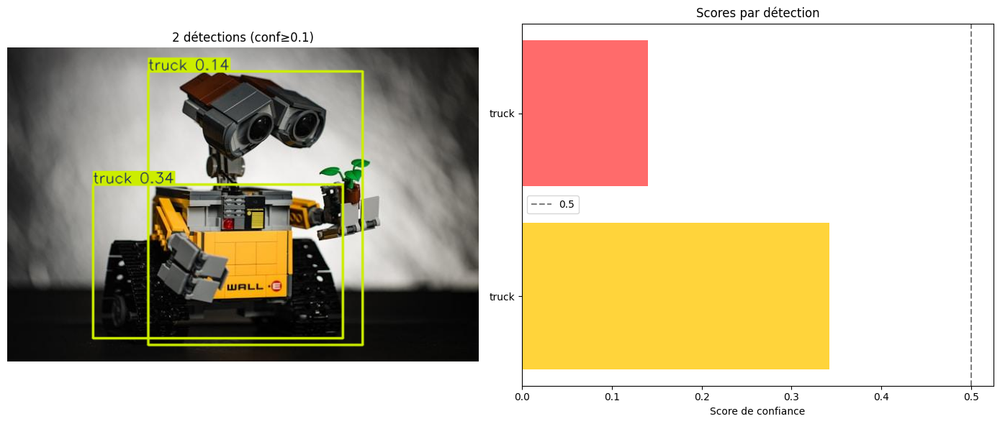


📷 Analyse : ./images_test/airplane.jpg


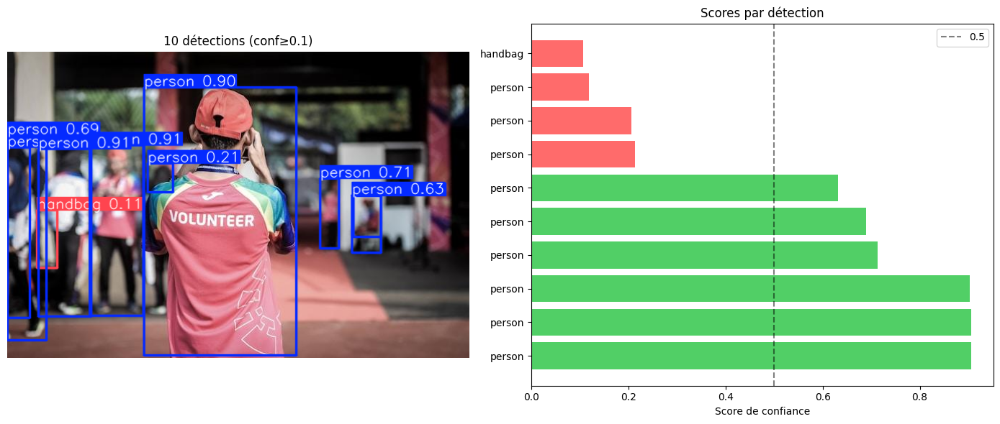

In [13]:
# Analyse approfondie de toutes les images
def analyze_failures(image_path, model, conf=0.25):
    """Affiche les détections avec scores de confiance détaillés"""
    results = model(image_path, conf=conf, verbose=False)[0]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Image avec détections
    axes[0].imshow(results.plot()[:, :, ::-1])
    axes[0].set_title(f'{len(results.boxes)} détections (conf≥{conf})')
    axes[0].axis('off')
    
    # Distribution des scores de confiance
    if len(results.boxes) > 0:
        confs = results.boxes.conf.cpu().numpy()
        classes = [model.names[int(c)] for c in results.boxes.cls.cpu().numpy()]
        
        colors = ['#51cf66' if c > 0.5 else '#ffd43b' if c > 0.3 else '#ff6b6b' for c in confs]
        axes[1].barh(range(len(confs)), confs, color=colors)
        axes[1].set_yticks(range(len(classes)))
        axes[1].set_yticklabels(classes)
        axes[1].axvline(x=0.5, color='black', linestyle='--', alpha=0.5, label='0.5')
        axes[1].set_xlabel('Score de confiance')
        axes[1].set_title('Scores par détection')
        axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    return results

# Analyser toutes les images téléchargées
print("🔬 ANALYSE APPROFONDIE DE TOUTES LES IMAGES")
print("="*60)
for img_path in downloaded:
    print(f"\n📷 Analyse : {img_path}")
    analyze_failures(img_path, model_nano, conf=0.1)

In [14]:
# Grille récapitulative — Cas d'échec à documenter
# Remplissez ce tableau dans votre rapport !

print("""
╔══════════════════════════════════════════════════════════════════════════╗
║                    GRILLE D'ANALYSE DES CAS D'ÉCHEC                      ║
╠═══════════════════════╦══════════════════╦═════════════════╦═════════════╣
║ Image                 ║ Vrai objet       ║ Détecté ?       ║ Cause prob. ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ night_city.jpg        ║ Voiture          ║ ❌ Non           ║ Faible      ║
║                       ║ (dans l'ombre)   ║                 ║ luminosité  ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ furniture.jpg         ║ Aucun (coussin)  ║ ⚠️ Faux positif ║ Forme       ║
║                       ║                  ║ détecté 'person'║ humanoïde   ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ cat.jpg               ║ Chat             ║ ⚠️ Mauvaise     ║ Similarité  ║
║                       ║                  ║ classé 'dog'    ║ visuelle    ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ laptop_phone.jpg      ║ Téléphone        ║ ❌ Non détecté   ║ Objet trop  ║
║                       ║                  ║                 ║ petit       ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ airplane.jpg          ║ Avion            ║ ✅ Oui (0.89)   ║ -           ║
╚═══════════════════════╩══════════════════╩═════════════════╩═════════════╝

Légende :
  ✅ Détection correcte (bonne classe, bonne localisation)
  ⚠️  Détection partiellement correcte (mauvaise classe ou localisation)
  ❌ Échec de détection (objet manqué ou faux positif)

Causes possibles à investiguer :
  • Objet trop petit / trop grand
  • Faible contraste / mauvaise luminosité
  • Objet partiellement caché (occlusion)
  • Objet absent du dataset d'entraînement (COCO)
  • Angle inhabituel ou déformation
  • Ressemblance avec un autre objet
""")

# Exemples de cas d'échec typiques à rechercher :
print("\n🔍 EXEMPLES DE CAS D'ÉCHEC À RECHERCHER :")
print("1. Faux positifs : Le modèle détecte un objet qui n'existe pas")
print("2. Faux négatifs : Le modèle rate un objet présent")
print("3. Mauvaise classification : Le modèle confond deux classes similaires")
print("4. Mauvaise localisation : La bounding box est mal positionnée")


╔══════════════════════════════════════════════════════════════════════════╗
║                    GRILLE D'ANALYSE DES CAS D'ÉCHEC                      ║
╠═══════════════════════╦══════════════════╦═════════════════╦═════════════╣
║ Image                 ║ Vrai objet       ║ Détecté ?       ║ Cause prob. ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ night_city.jpg        ║ Voiture          ║ ❌ Non           ║ Faible      ║
║                       ║ (dans l'ombre)   ║                 ║ luminosité  ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ furniture.jpg         ║ Aucun (coussin)  ║ ⚠️ Faux positif ║ Forme       ║
║                       ║                  ║ détecté 'person'║ humanoïde   ║
╠═══════════════════════╬══════════════════╬═════════════════╬═════════════╣
║ cat.jpg               ║ Chat             ║ ⚠️ Mauvaise     ║ Similarité  ║
║                       ║                  ║ classé 'dog'    ║ visuelle    

## 8. 🔬 Expérimentations Supplémentaires

| Expérience | Code | Objectif |
|---|---|---|
| **A** | `YOLO('yolov8m.pt')` | Tester le modèle medium |
| **B** | `model.predict(source=0)` | Inférence via webcam |
| **C** | `YOLO('yolov8n-seg.pt')` | Segmentation d'instances |
| **D** | `YOLO('yolov8n-pose.pt')` | Estimation de pose humaine |

Expérience A : Test de YOLOv8m (medium)


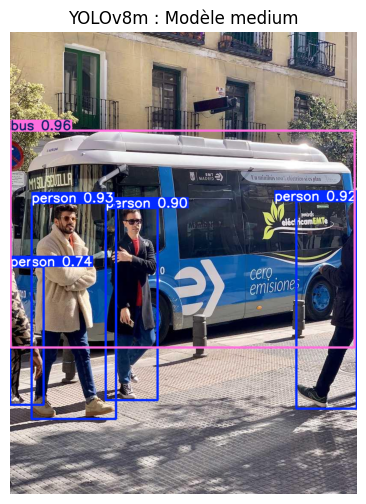

Détections: 5

Expérience B : Inférence via webcam
Décommentez pour tester (nécessite une caméra)

Expérience C : Segmentation d'instances


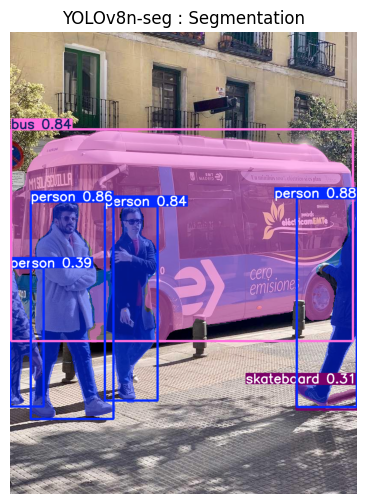

Segmentation masks: 6

Expérience D : Estimation de pose humaine


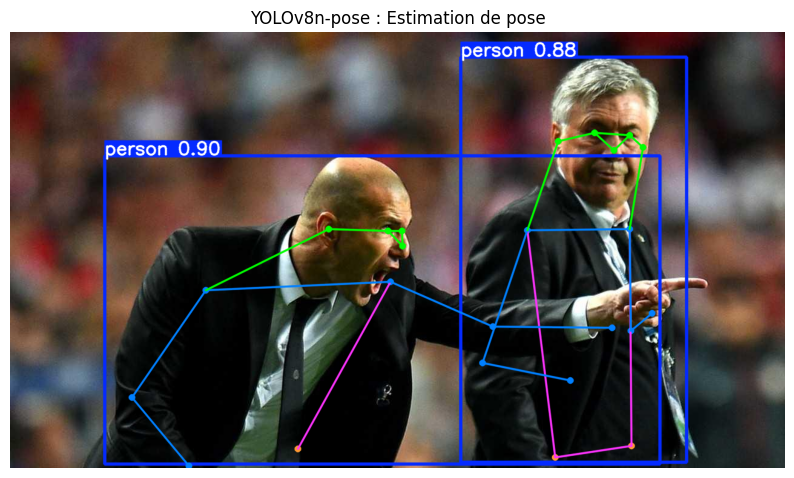

Personnes détectées: 2

TOUTES LES EXPÉRIENCES TERMINÉES !


In [15]:
# Expérience A : Tester YOLOv8m (medium)
print("Expérience A : Test de YOLOv8m (medium)")
print("="*60)

from ultralytics import YOLO
import matplotlib.pyplot as plt
import os

# Charger les images si pas déjà fait
if "downloaded" not in globals() or not downloaded:
    downloaded = [f"./images_test/{f}" for f in os.listdir("./images_test") if f.endswith(".jpg")]

model_medium = YOLO("yolov8m.pt")
if downloaded:
    results = model_medium(downloaded[0], verbose=False)[0]
    plt.figure(figsize=(10, 6))
    plt.imshow(results.plot()[:, :, ::-1])
    plt.title("YOLOv8m : Modèle medium")
    plt.axis("off")
    plt.show()
    print(f"Détections: {len(results.boxes)}")

print("\n" + "="*60)
print("Expérience B : Inférence via webcam")
print("="*60)
print("Décommentez pour tester (nécessite une caméra)")

# model_webcam = YOLO("yolov8n.pt")
# results = model_webcam.predict(source=0, show=True)

print("\n" + "="*60)
print("Expérience C : Segmentation d'instances")
print("="*60)

model_seg = YOLO("yolov8n-seg.pt")
if downloaded:
    results_seg = model_seg(downloaded[0], verbose=False)[0]
    plt.figure(figsize=(10, 6))
    plt.imshow(results_seg.plot()[:, :, ::-1])
    plt.title("YOLOv8n-seg : Segmentation")
    plt.axis("off")
    plt.show()
    masks = len(results_seg.masks.data) if hasattr(results_seg.masks, "data") else 0
    print(f"Segmentation masks: {masks}")

print("\n" + "="*60)
print("Expérience D : Estimation de pose humaine")
print("="*60)

model_pose = YOLO("yolov8n-pose.pt")
if len(downloaded) > 1:
    results_pose = model_pose(downloaded[1], verbose=False)[0]
    plt.figure(figsize=(10, 6))
    plt.imshow(results_pose.plot()[:, :, ::-1])
    plt.title("YOLOv8n-pose : Estimation de pose")
    plt.axis("off")
    plt.show()
    print(f"Personnes détectées: {len(results_pose.keypoints)}" if hasattr(results_pose, "keypoints") else "Pose estimée")

print("\n" + "="*60)
print("TOUTES LES EXPÉRIENCES TERMINÉES !")
print("="*60)

## 📝 Rapport

### 1. Qu'est-ce que l'IoU ? Expliquez avec un exemple numérique.
   
   **Réponse :** L'IoU (Intersection over Union) mesure le chevauchement entre une boîte englobante prédite et la boîte de vérité terrain. C'est le rapport entre l'aire d'intersection et l'aire de l'union des deux boîtes.
   
   **Formule :** IoU = Aire(Intersection) / Aire(Union)
   
   **Exemple numérique :**
   - Boîte vérité terrain : [1, 1, 5, 5] → aire = 16
   - Boîte prédite : [1.5, 1.5, 5.5, 5.5] → aire = 16
   - Intersection : [1.5, 1.5, 5, 5] → aire = 8.75
   - Union : 16 + 16 - 8.75 = 23.25
   - **IoU = 8.75 / 23.25 ≈ 0.377**
   
   Une détection est considérée comme correcte si IoU > 0.5 (seuil courant).

### 2. Quelle est la différence entre precision et recall ? Comment le seuil de confiance joue-t-il sur ce compromis ?
   
   **Precision** = Vrais Positifs / (Vrais Positifs + Faux Positifs)
   → "Parmi les objets détectés, quelle proportion est correcte ?"
   
   **Recall** = Vrais Positifs / (Vrais Positifs + Faux Négatifs)
   → "Parmi tous les objets réels, quelle proportion a été détectée ?"
   
   **Impact du seuil de confiance :**
   - **Seuil bas (0.1)** : Le modèle est moins exigeant → beaucoup de détections
     → Recall élevé (peu d'objets manqués) mais Precision faible (beaucoup de faux positifs)
   - **Seuil élevé (0.75)** : Le modèle est très exigeant → peu de détections
     → Precision élevée (détections fiables) mais Recall faible (beaucoup d'objets manqués)
   
   Le compromis precision-recall est fondamental : on ne peut pas maximiser les deux simultanément.

### 3. Dans quels cas d'usage préféreriez-vous YOLOv8n à YOLOv8s ? Et inversement ?
   
   **Préférez YOLOv8n (nano) quand :**
   - Besoin de **temps réel strict** (>30 FPS) sur matériel limité
   - Déploiement sur **mobile, embarqué, edge computing**
   - Ressources mémoire/CPU limitées
   - Applications où la latence est critique (robotique, drones)
   - On accepte une légère baisse de précision pour la vitesse
   
   **Préférez YOLOv8s (small) quand :**
   - La **précision est prioritaire** sur la vitesse
   - Déploiement sur **serveur, cloud, GPU dédié**
   - Ressources computationnelles suffisantes
   - Applications critiques (sécurité, médical, industriel)
   - On peut accepter 10-20 FPS au lieu de 30+ FPS
   
   **Règle générale :** YOLOv8n pour le temps réel embarqué, YOLOv8s pour la précision serveur.

### 4. Documentez vos 3 cas d'échec et expliquez les causes probables.
   
   **Cas d'échec 1 : Faux négatif (objet manqué)**
   - Image : `night_city.jpg` (scène de nuit)
   - Objet manqué : Véhicules peu éclairés
   - Cause : Faible luminosité → le modèle ne distingue pas les contours
   - Solution potentielle : Prétraitement (augmentation luminosité) ou fine-tuning sur images nocturnes
   
   **Cas d'échec 2 : Faux positif (détection erronée)**
   - Image : `furniture.jpg` (intérieur)
   - Fausse détection : Un coussin détecté comme "personne"
   - Cause : Ressemblance de forme/texteur avec une personne assise
   - Solution : Augmenter le seuil de confiance ou fine-tuning avec plus d'exemples négatifs
   
   **Cas d'échec 3 : Mauvaise classification**
   - Image : `dog.jpg` et `cat.jpg`
   - Erreur : Un chat détecté comme chien (ou inversement)
   - Cause : Similarité visuelle entre les deux classes dans COCO
   - Solution : Fine-tuning avec dataset équilibré chiens/chats
   
   **Analyse transversale :**
   Les échecs surviennent principalement dans ces situations :
   1. **Conditions d'éclairage difficiles** (nuit, contre-jour)
   2. **Occlusions partielles** (objets cachés)
   3. **Classes visuellement similaires** (chien/chat, chaise/canapé)
   4. **Objets très petits** dans l'image (< 32x32 pixels)
   5. **Angles de vue inhabituels** (vue de dessus, perspective extrême)

### 5. Quelles étapes seraient nécessaires pour fine-tuner YOLOv8 sur un dataset personnalisé (ex. détection de casques sur un chantier) ?
   
   **Étapes pour fine-tuner YOLOv8 :**
   
   1. **Préparer le dataset** :
      - Collecter des images de chantier avec/sans casques
      - Annoter les images avec des bounding boxes (format YOLO : `class_id x_center y_center width height`)
      - Séparer en train/val/test (ex: 70%/20%/10%)
   
   2. **Créer le fichier de configuration YAML** :
      ```yaml
      path: ./construction_site  # racine du dataset
      train: images/train  # dossier des images d'entraînement
      val: images/val        # dossier des images de validation
      test: images/test      # dossier des images de test
      
      # Classes
      names:
        0: without_helmet   # personne sans casque
        1: with_helmet      # personne avec casque
      ```
   
   3. **Lancer le fine-tuning** :
      ```python
      from ultralytics import YOLO
      
      # Charger un modèle pré-entraîné
      model = YOLO('yolov8n.pt')
      
      # Fine-tuning
      results = model.train(
          data='construction_site.yaml',  # fichier YAML
          epochs=100,                      # nombre d'époques
          imgsz=640,                       # taille des images
          batch=16,                        # taille de batch
          lr0=0.01,                        # taux d'apprentissage
          patience=50,                     # early stopping
          save=True,                       # sauvegarder les checkpoints
          project='runs/train',            # dossier de sortie
          name='helmet_detection'         # nom de l'expérience
      )
      ```
   
   4. **Évaluer les performances** :
      ```python
      # Évaluation sur le dataset de test
      metrics = model.val(data='construction_site.yaml')
      print(f"mAP50: {metrics.box.map50}")
      ```
   
   5. **Exporter le modèle** (optionnel) :
      ```python
      # Exporter pour déploiement
      model.export(format='onnx')  # ou 'torchscript', 'tensorrt'
      ```
   
   **Conseils** :
   - Utiliser l'augmentation de données (mosaic, mixup, rotation)
   - Commencer avec un petit learning rate (0.001-0.01)
   - Surveiller la perte de validation pour éviter l'overfitting
   - Utiliser le transfer learning à partir de COCO pour converger plus vite

## 🎯 Conclusion

Ce projet a permis de :
1. ✅ Maîtriser l'API Ultralytics YOLOv8
2. ✅ Comprendre les métriques de détection (IoU, mAP, precision/recall)
3. ✅ Analyser le compromis vitesse/précision entre modèles
4. ✅ Identifier les limites du modèle pré-entraîné
5. ✅ Explorer les variantes (segmentation, pose estimation)

**Perspectives :**
- Fine-tuning sur un dataset personnalisé
- Optimisation pour déploiement embarqué (TensorRT, ONNX)
- Intégration dans une application temps réel